# Avaliar os resultados e fechar as conclusões
**Fase 5 — Avaliação | CRISP-DM**

Já temos os dados preparados e as previsões guardadas. Agora vamos perceber o que os resultados permitem concluir e se respondem ao problema definido no `01`.

A pergunta da previsão mantém-se: **o histórico permite prever a percentagem sem médico do mês seguinte melhor do que repetir o último valor?** Vamos responder para os modelos, unidades, meses e recolha que testámos. Não vamos generalizar para todos os modelos possíveis nem para o novo indicador de julho de 2026.

Este notebook tem duas partes: avaliar as previsões no teste reservado e reunir as respostas descritivas e a avaliação das quatro hipóteses. O valor da análise da cobertura não depende de os modelos ganharem à referência.

| Elemento | O que vamos usar |
|---|---|
| Teste | Meses-alvo de janeiro a junho de 2026, nas 38 séries completas. |
| Escolha do modelo | A seleção feita no `04`, pela validação; não muda nesta fase. |
| Métrica principal | MAE em pontos percentuais, nas mesmas linhas para todas as abordagens. |
| Análise descritiva | Todos os 39 registos mensais do principal; séries completas para variação por unidade. |
| Geografia | Faixas de inscritos fixadas no primeiro mês, com indicação de grupos pequenos. |
| Consultas | Q5 continua pendente da confirmação da janela exata do indicador. |

**Execução:** usar o mesmo kernel, com `pandas`, `numpy` e `matplotlib`. Não é necessário importar `scikit-learn`, carregar os modelos ou voltar a treiná-los. Executar por ordem com **Run All**. Os ficheiros do `03` e `04` são apenas lidos.

## 1. Ler e conferir as entradas

A assinatura dos ficheiros permite verificar que não foram alterados depois de preparados ou usados na modelação. O valor observado de cada previsão será também conferido contra a série preparada da mesma unidade no mês-alvo.

O notebook cria `data/analytics/`, `data/output/` e `docs/` quando necessário. Ao repetir, atualiza apenas os resultados e notas desta fase.

In [1]:
from pathlib import Path, PureWindowsPath
import hashlib
import json
from itertools import combinations
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from IPython.display import display

atual = Path.cwd().resolve()
raiz = next((p for p in [atual, *atual.parents]
             if (p / "notebooks").is_dir() and (p / "data").is_dir()), None)
if raiz is None:
    raise FileNotFoundError("Abrir a pasta do projeto, com notebooks/ e data/.")
PASTA_OUTPUT = raiz / "data" / "output"
PASTA_ANALYTICS = raiz / "data" / "analytics"
PASTA_MODELS = raiz / "data" / "models"
PASTA_DOCS = raiz / "docs"
for pasta in [PASTA_OUTPUT, PASTA_ANALYTICS, PASTA_DOCS]:
    pasta.mkdir(parents=True, exist_ok=True)

nomes_output = ["sns_csp_principal.csv", "sns_csp_series_completas.csv", "sns_csp_regional.csv",
                "sns_faixas_dimensao.json", "sns_preparacao_manifesto.json", "sns_previsoes_teste.csv"]
entradas = [PASTA_OUTPUT / n for n in nomes_output] + [
    PASTA_MODELS / "04_selecao_modelo.json", PASTA_MODELS / "04_execucao_modelacao.json"]
faltam = [str(p.relative_to(raiz)) for p in entradas if not p.is_file()]
if faltam:
    raise FileNotFoundError(f"Faltam resultados do 03/04: {faltam}. Executar essas fases primeiro.")

def sha256(p):
    return hashlib.sha256(p.read_bytes()).hexdigest()

def guardar_csv(t, nome, pasta=PASTA_ANALYTICS):
    t.to_csv(pasta / nome, index=False, encoding="utf-8-sig", date_format="%Y-%m-%d")

def guardar_grafico(fig, nome):
    fig.tight_layout()
    fig.savefig(PASTA_ANALYTICS / nome, dpi=160, bbox_inches="tight")
    plt.show()
    plt.close(fig)

assinaturas_antes = {p.relative_to(raiz).as_posix(): sha256(p) for p in entradas}
manifesto = json.loads((PASTA_OUTPUT / "sns_preparacao_manifesto.json").read_text(encoding="utf-8"))
selecao = json.loads((PASTA_MODELS / "04_selecao_modelo.json").read_text(encoding="utf-8"))
execucao_04 = json.loads((PASTA_MODELS / "04_execucao_modelacao.json").read_text(encoding="utf-8"))
faixas = json.loads((PASTA_OUTPUT / "sns_faixas_dimensao.json").read_text(encoding="utf-8"))
for registo in manifesto["outputs"]:
    if registo["ficheiro"] in nomes_output:
        if sha256(PASTA_OUTPUT / registo["ficheiro"]) != registo["sha256"]:
            raise ValueError(f"Entrada diferente da preparação: {registo['ficheiro']}.")
# O 04 pode ter sido executado em Windows (\) ou Linux/macOS (/).
# Normalizar as chaves do registo; os ficheiros continuam a ser verificados.
assinaturas_resultados = {
    PureWindowsPath(nome).as_posix(): assinatura
    for nome, assinatura in execucao_04["resultados_sha256"].items()
}
for nome in ["data/output/sns_previsoes_teste.csv", "data/models/04_selecao_modelo.json"]:
    if nome not in assinaturas_resultados:
        raise ValueError(f"Falta a assinatura de {nome} no registo do 04. Rever a execução do 04.")
    if sha256(raiz / nome) != assinaturas_resultados[nome]:
        raise ValueError(f"Resultado do 04 alterado: {nome}.")
if sha256(PASTA_OUTPUT / "sns_preparacao_manifesto.json") != execucao_04["input_sha256"]["sns_preparacao_manifesto.json"]:
    raise ValueError("O 04 usou outro manifesto de preparação. Reexecutar as fases dependentes.")
if selecao["selecionado"] != execucao_04["selecionado"]:
    raise ValueError("A seleção e o registo de execução do 04 não coincidem.")

principal = pd.read_csv(PASTA_OUTPUT / "sns_csp_principal.csv", parse_dates=["mes"])
series = pd.read_csv(PASTA_OUTPUT / "sns_csp_series_completas.csv", parse_dates=["mes"])
regional = pd.read_csv(PASTA_OUTPUT / "sns_csp_regional.csv", parse_dates=["mes"])
previsoes = pd.read_csv(PASTA_OUTPUT / "sns_previsoes_teste.csv", parse_dates=["mes", "mes_alvo"])
CHAVE = ["regiao_saude", "unidade_fonte", "mes"]
selecionado = selecao["selecionado"]
rf = selecao["configuracao_rf_selecionada"]
ABORDAGENS = ["ultimo_valor", "regressao_linear", rf]
ROTULOS = {"ultimo_valor": "Último valor", "regressao_linear": "Regressão linear",
           "random_forest_a": "Random Forest A", "random_forest_b": "Random Forest B"}
COL_PREV = [f"prev_{n}_pct" for n in ABORDAGENS]

verdade = series[["regiao_saude", "unidade_fonte", "mes", "sem_medico_pct"]].rename(
    columns={"mes": "mes_alvo", "sem_medico_pct": "observado_preparado"})
conferencia = previsoes.merge(verdade, on=["regiao_saude", "unidade_fonte", "mes_alvo"],
                             how="left", validate="many_to_one")
origem = series[[*CHAVE, "sem_medico_pct"]].rename(columns={"sem_medico_pct": "valor_origem"})
conferencia = conferencia.merge(origem, on=CHAVE, how="left", validate="many_to_one")
INICIO = pd.Timestamp(manifesto["inicio_principal"])
FIM = pd.Timestamp(manifesto["fim_principal"])
MESES_TESTE = pd.date_range(selecao["teste_primeiro_mes_alvo"], selecao["teste_ultimo_mes_alvo"], freq="MS")
checks = pd.DataFrame([
    ["Chaves de previsão únicas", not previsoes.duplicated(CHAVE).any()],
    ["Pares de meses consecutivos", previsoes["mes_alvo"].eq(previsoes["mes"] + pd.offsets.MonthBegin(1)).all()],
    ["Teste só nos meses reservados", set(previsoes["mes_alvo"]) == set(MESES_TESTE)],
    ["Todas as séries têm todos os meses de teste", len(previsoes) > 0 and previsoes.groupby(["regiao_saude", "unidade_fonte"])["mes_alvo"].nunique().eq(len(MESES_TESTE)).all()],
    ["Observados correspondem ao mês-alvo preparado", conferencia["observado_preparado"].notna().all() and np.allclose(conferencia["observado_pct"], conferencia["observado_preparado"], rtol=0, atol=1e-10)],
    ["Referência repete o mês de origem", conferencia["valor_origem"].notna().all() and np.allclose(conferencia["prev_ultimo_valor_pct"], conferencia["valor_origem"], rtol=0, atol=1e-10)],
    ["Mesmas linhas e valores finitos nas três abordagens", np.isfinite(previsoes[COL_PREV + ["observado_pct"]].to_numpy()).all()],
    ["Seleção guardada corresponde à coluna selecionada", np.allclose(previsoes["prev_selecionado_pct"], previsoes[f"prev_{selecionado}_pct"], rtol=0, atol=1e-10) and previsoes["abordagem_selecionada"].eq(selecionado).all()],
    ["Principal com chave única e categorias coerentes", not principal.duplicated(CHAVE).any() and principal[["com_medico", "sem_medico", "sem_medico_opcao"]].sum(axis=1).eq(principal["inscritos"]).all()],
], columns=["verificacao", "passou"])
checks["passou"] = checks["passou"].astype(bool)
guardar_csv(checks, "05_validacoes_entrada.csv")
display(checks)
if not checks["passou"].all():
    raise ValueError("As entradas não passaram todas as verificações. Rever antes de avaliar.")
plt.rcParams.update({"figure.dpi": 110, "font.size": 10, "axes.spines.top": False, "axes.spines.right": False})
print("Teste:", len(previsoes), "linhas;", previsoes["unidade_fonte"].nunique(), "unidades.")
print("Seleção feita no 04:", ROTULOS[selecionado])

,verificacao,passou
0,Chaves de previsão únicas,True
1,Pares de meses consecutivos,True
2,Teste só nos meses reservados,True
3,Todas as séries têm todos os meses de teste,True
4,Observados correspondem ao mês-alvo preparado,True
5,Referência repete o mês de origem,True
6,Mesmas linhas e valores finitos nas três abord...,True
7,Seleção guardada corresponde à coluna selecionada,True
8,Principal com chave única e categorias coerentes,True


Teste: 228 linhas; 38 unidades.
Seleção feita no 04: Último valor


## 2. Comparar o erro no teste

Cada linha de teste tem o observado e as previsões das três abordagens. O MAE dá o mesmo peso a cada unidade/mês; não está ponderado pelo número de inscritos. É o critério definido para comparar a previsão de percentagens.

| Medida | Leitura |
|---|---|
| MAE | Erro absoluto médio, em pontos percentuais; menor é melhor. |
| RMSE | Dá mais peso a erros grandes; também em pontos percentuais. |
| Viés | Média de previsto menos observado; negativo indica subestimação. |
| Ganho face à referência | MAE da referência menos MAE da abordagem; positivo indica melhoria. |

A coluna `selecionado_no_04` identifica a escolha já feita. A tabela pode ser ordenada pelo erro para leitura, mas isso não constitui uma nova seleção pelo teste.

,abordagem,selecionado_no_04,linhas,mae_pp,rmse_pp,vies_pp,mediana_erro_absoluto_pp,p90_erro_absoluto_pp,maximo_erro_absoluto_pp,ganho_face_referencia_pp,reducao_erro_pct
0,ultimo_valor,True,228,0.4174,0.6793,-0.1654,0.1920,1.0649,3.3482,0.0000,0.0000
1,regressao_linear,False,228,0.4489,0.6965,-0.1892,0.2719,1.0329,3.6298,-0.0316,-7.5618
2,random_forest_b,False,228,0.5822,0.8416,-0.2891,0.3763,1.4109,3.4198,-0.1648,-39.4867


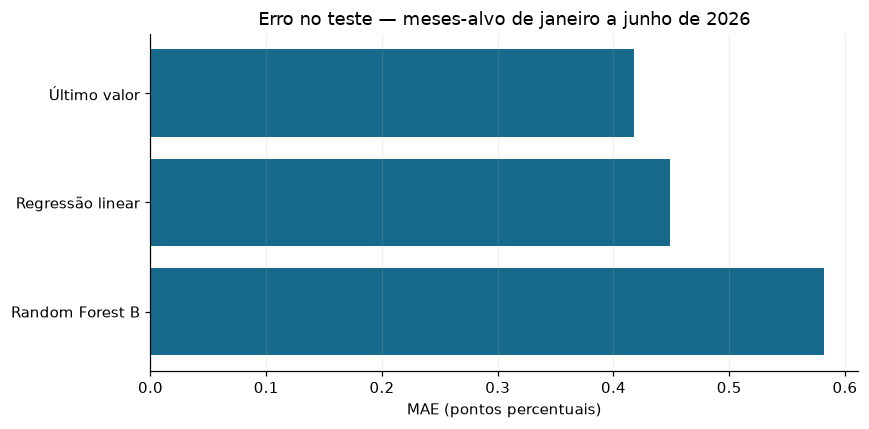

Ganho da abordagem selecionada face à referência: 0.0 pp
Critério de superar a referência: não cumprido


In [2]:
def calcular_metricas(observado, previsto):
    erro = np.asarray(previsto, dtype=float) - np.asarray(observado, dtype=float)
    return {"mae_pp": float(np.abs(erro).mean()), "rmse_pp": float(np.sqrt((erro ** 2).mean())),
            "vies_pp": float(erro.mean()), "mediana_erro_absoluto_pp": float(np.median(np.abs(erro))),
            "p90_erro_absoluto_pp": float(np.quantile(np.abs(erro), 0.90)),
            "maximo_erro_absoluto_pp": float(np.abs(erro).max())}
metricas = pd.DataFrame([{
    "abordagem": nome, "selecionado_no_04": nome == selecionado, "linhas": len(previsoes),
    **calcular_metricas(previsoes["observado_pct"], previsoes[f"prev_{nome}_pct"]),
} for nome in ABORDAGENS])
mae_ref = float(metricas.set_index("abordagem").loc["ultimo_valor", "mae_pp"])
metricas["ganho_face_referencia_pp"] = mae_ref - metricas["mae_pp"]
metricas["reducao_erro_pct"] = (100 * metricas["ganho_face_referencia_pp"] / mae_ref) if mae_ref > 0 else np.nan
mae_selecionado = float(metricas.set_index("abordagem").loc[selecionado, "mae_pp"])
ganho_selecionado = mae_ref - mae_selecionado
melhor_aprendido_validacao = selecao["melhor_candidato_aprendido"]
mae_aprendido_validacao = float(metricas.set_index("abordagem").loc[melhor_aprendido_validacao, "mae_pp"])
supera_referencia = selecionado != "ultimo_valor" and ganho_selecionado > selecao["tolerancia_empate_pp"]
guardar_csv(metricas, "05_metricas_teste.csv")
display(metricas.round(4))

fig, ax = plt.subplots(figsize=(8, 4))
ordenada = metricas.sort_values("mae_pp", ascending=False)
ax.barh([ROTULOS[n] for n in ordenada["abordagem"]], ordenada["mae_pp"], color="#176a8b")
ax.set(title="Erro no teste — meses-alvo de janeiro a junho de 2026", xlabel="MAE (pontos percentuais)")
ax.grid(axis="x", alpha=0.18)
guardar_grafico(fig, "05_mae_teste.png")
print("Ganho da abordagem selecionada face à referência:", round(ganho_selecionado, 4), "pp")
print("Critério de superar a referência:", "cumprido" if supera_referencia else "não cumprido")

## 3. Verificar se o resultado se repete entre meses e unidades

O erro global pode esconder diferenças. Vamos calcular o MAE por mês-alvo e por unidade, sempre nas mesmas linhas para todas as abordagens.

O ganho positivo numa unidade significa menor MAE do que a referência nos seis meses dessa unidade. Não vamos substituir o modelo unidade a unidade com base neste teste: isso seria outra seleção feita depois de observar o resultado.

As 228 linhas não são 228 observações independentes. Há repetição das mesmas unidades e dependência entre meses; os seis meses de teste também limitam a generalização. Apresentamos os padrões observados sem lhes atribuir significância estatística.

,abordagem,unidades_com_menor_mae_que_referencia,unidades_com_maior_mae_que_referencia,unidades_empatadas
0,ultimo_valor,0,0,38
1,regressao_linear,13,25,0
2,random_forest_b,9,29,0


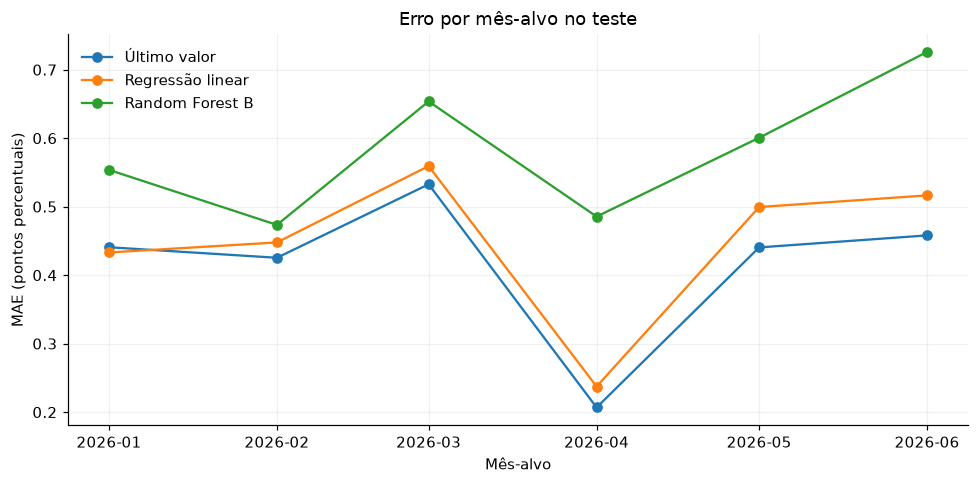

In [3]:
partes = []
for nome in ABORDAGENS:
    t = previsoes[CHAVE + ["mes_alvo", "observado_pct"]].copy()
    t["abordagem"] = nome
    t["previsto_pct"] = previsoes[f"prev_{nome}_pct"].to_numpy()
    t["erro_pp"] = t["previsto_pct"] - t["observado_pct"]
    t["erro_absoluto_pp"] = t["erro_pp"].abs()
    partes.append(t)
erros = pd.concat(partes, ignore_index=True)
por_mes = (erros.groupby(["mes_alvo", "abordagem"])
    .agg(linhas=("erro_pp", "size"), mae_pp=("erro_absoluto_pp", "mean"), vies_pp=("erro_pp", "mean"))
    .reset_index())
por_unidade = (erros.groupby(["regiao_saude", "unidade_fonte", "abordagem"])
    .agg(meses=("mes_alvo", "nunique"), mae_pp=("erro_absoluto_pp", "mean"), vies_pp=("erro_pp", "mean"))
    .reset_index())
mae_unidades = por_unidade.pivot(index=["regiao_saude", "unidade_fonte"], columns="abordagem", values="mae_pp")
ganhos_unidades = mae_unidades.copy()
for nome in ABORDAGENS:
    ganhos_unidades[f"ganho_{nome}_pp"] = mae_unidades["ultimo_valor"] - mae_unidades[nome]
resumo_ganhos = pd.DataFrame([{
    "abordagem": nome,
    "unidades_com_menor_mae_que_referencia": int(ganhos_unidades[f"ganho_{nome}_pp"].gt(1e-10).sum()),
    "unidades_com_maior_mae_que_referencia": int(ganhos_unidades[f"ganho_{nome}_pp"].lt(-1e-10).sum()),
    "unidades_empatadas": int(ganhos_unidades[f"ganho_{nome}_pp"].abs().le(1e-10).sum()),
} for nome in ABORDAGENS])
guardar_csv(erros, "sns_erros_teste.csv", PASTA_OUTPUT)
guardar_csv(por_mes, "05_erros_por_mes.csv")
guardar_csv(por_unidade, "05_erros_por_unidade.csv")
guardar_csv(ganhos_unidades.reset_index(), "05_ganhos_por_unidade.csv")
guardar_csv(resumo_ganhos, "05_resumo_ganhos_unidades.csv")
display(resumo_ganhos)

fig, ax = plt.subplots(figsize=(9, 4.5))
for nome in ABORDAGENS:
    t = por_mes.loc[por_mes["abordagem"].eq(nome)]
    ax.plot(t["mes_alvo"], t["mae_pp"], marker="o", label=ROTULOS[nome])
ax.set(title="Erro por mês-alvo no teste", xlabel="Mês-alvo", ylabel="MAE (pontos percentuais)")
ax.xaxis.set_major_locator(mdates.MonthLocator())
ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y-%m"))
ax.legend(frameon=False)
ax.grid(alpha=0.18)
guardar_grafico(fig, "05_mae_por_mes.png")

## 4. Observar os maiores erros da abordagem selecionada

Vamos manter a seleção do `04` e ver onde falhou mais. Um erro negativo significa que a percentagem observada ficou acima da previsão.

O gráfico de observado versus previsto pode parecer muito bom só porque as unidades têm níveis de cobertura muito diferentes. A proximidade à diagonal não substitui a comparação do MAE com a referência.

Os maiores erros podem orientar uma investigação de alterações de registo, de cobertura ou de território. Este dataset, por si só, não permite identificar a causa desses movimentos.

C:\Users\Tiago\AppData\Local\Temp\ipykernel_14976\2995512282.py:4: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  display(maiores_erros[["unidade_fonte", "mes_alvo", "observado_pct", "previsto_pct", "erro_pp"]].round(3))


,unidade_fonte,mes_alvo,observado_pct,previsto_pct,erro_pp
22,CSP da ULS Litoral Alentejano,2026-05-01,33.489,30.141,-3.348
58,CSP da ULS Guarda,2026-05-01,12.512,9.533,-2.979
92,CSP da ULS Arco Ribeirinho,2026-03-01,37.528,35.367,-2.161
85,CSP da ULS Amadora / Sintra,2026-02-01,31.440,33.582,2.142
18,CSP da ULS Litoral Alentejano,2026-01-01,29.524,27.432,-2.093
47,CSP da ULS Coimbra,2026-06-01,4.559,6.614,2.055
38,CSP da ULS Castelo Branco,2026-03-01,22.064,20.060,-2.004
50,CSP da ULS Cova da Beira,2026-03-01,13.915,12.125,-1.791
5,CSP da ULS Alentejo Central,2026-06-01,9.237,7.489,-1.748
48,CSP da ULS Cova da Beira,2026-01-01,12.458,10.710,-1.748


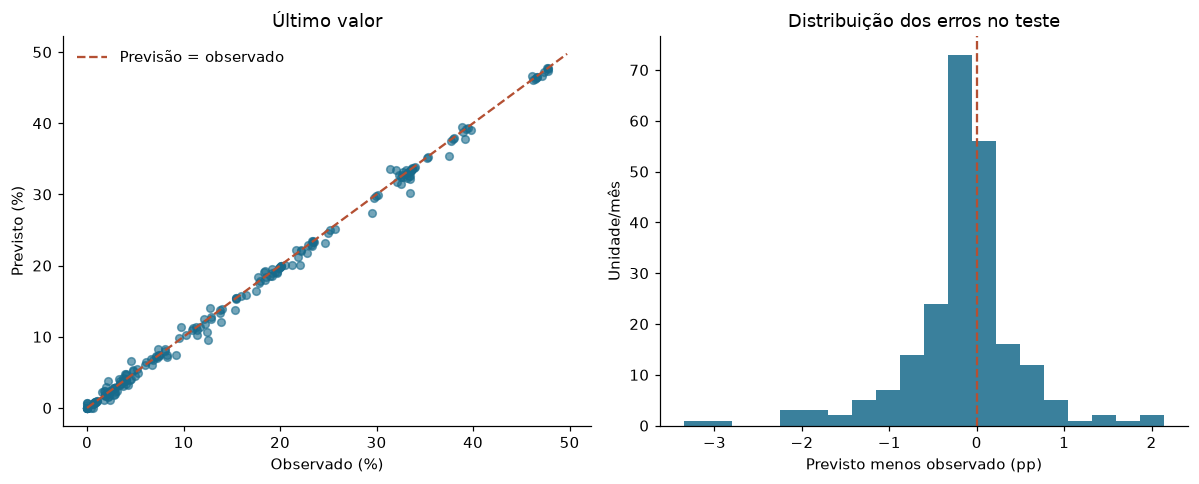

In [4]:
erros_selecionado = erros.loc[erros["abordagem"].eq(selecionado)].copy()
maiores_erros = erros_selecionado.nlargest(10, "erro_absoluto_pp")
guardar_csv(maiores_erros, "05_maiores_erros_selecionado.csv")
display(maiores_erros[["unidade_fonte", "mes_alvo", "observado_pct", "previsto_pct", "erro_pp"]].round(3))

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
axes[0].scatter(erros_selecionado["observado_pct"], erros_selecionado["previsto_pct"], alpha=0.6, s=25, color="#176a8b")
limite = max(float(erros_selecionado["observado_pct"].max()), float(erros_selecionado["previsto_pct"].max())) + 2
axes[0].plot([0, limite], [0, limite], color="#b45033", linestyle="--", label="Previsão = observado")
axes[0].set(xlabel="Observado (%)", ylabel="Previsto (%)", title=ROTULOS[selecionado])
axes[0].legend(frameon=False)
axes[1].hist(erros_selecionado["erro_pp"], bins=20, color="#176a8b", alpha=0.85)
axes[1].axvline(0, color="#b45033", linestyle="--")
axes[1].set(xlabel="Previsto menos observado (pp)", ylabel="Unidade/mês", title="Distribuição dos erros no teste")
guardar_grafico(fig, "05_erros_selecionado.png")

## 5. Reunir as respostas sobre cobertura e evolução — Q1 a Q4, H1 e H2

Voltamos ao dataset principal para os rankings do último mês e aos totais regionais para a evolução geográfica. A evolução por unidade usa as 38 séries completas. Não usamos o subconjunto da modelação para substituir a análise descritiva.

O ranking por número mede quantas pessoas da categoria estão afetadas. O ranking por percentagem mede a proporção no total de inscritos. A categoria por opção mantém-se separada.

Nas variações, um valor negativo em pontos percentuais representa redução da percentagem sem médico. As percentagens regionais continuam ponderadas pelos inscritos, em cada mês.

In [5]:
ultimo = principal.loc[principal["mes"].eq(FIM)].copy()
ultimo["posicao_numero"] = ultimo["sem_medico"].rank(ascending=False, method="average")
ultimo["posicao_percentagem"] = ultimo["sem_medico_pct"].rank(ascending=False, method="average")
ranking_numero = ultimo.sort_values("sem_medico", ascending=False)
ranking_pct = ultimo.sort_values("sem_medico_pct", ascending=False)
lider_numero = ranking_numero.iloc[0]
lider_pct = ranking_pct.iloc[0]
rho_rankings = float(ultimo["posicao_numero"].corr(ultimo["posicao_percentagem"]))
posicoes_diferentes = int(ultimo["posicao_numero"].ne(ultimo["posicao_percentagem"]).sum())
campos_ranking = ["mes", "regiao_saude", "unidade_fonte", "inscritos", "sem_medico", "sem_medico_pct", "posicao_numero", "posicao_percentagem"]
guardar_csv(ranking_numero[campos_ranking], "05_ranking_numero.csv")
guardar_csv(ranking_pct[campos_ranking], "05_ranking_percentagem.csv")
display(ranking_numero[campos_ranking].head(5).round(3))
display(ranking_pct[campos_ranking].head(5).round(3))

indices = ["regiao_saude", "unidade_fonte"]
inicio_unidade = series.loc[series["mes"].eq(INICIO), indices + ["inscritos", "sem_medico_pct"]]
fim_unidade = series.loc[series["mes"].eq(FIM), indices + ["inscritos", "sem_medico_pct"]]
evolucao = inicio_unidade.merge(fim_unidade, on=indices, suffixes=("_inicio", "_fim"), validate="one_to_one")
evolucao["variacao_sem_medico_pp"] = evolucao["sem_medico_pct_fim"] - evolucao["sem_medico_pct_inicio"]
evolucao["variacao_inscritos_pct"] = 100 * (evolucao["inscritos_fim"] / evolucao["inscritos_inicio"] - 1)
melhorou = int(evolucao["variacao_sem_medico_pp"].lt(-1e-10).sum())
piorou = int(evolucao["variacao_sem_medico_pp"].gt(1e-10).sum())
maior_melhoria = evolucao.nsmallest(1, "variacao_sem_medico_pp").iloc[0]
maior_agravamento = evolucao.nlargest(1, "variacao_sem_medico_pp").iloc[0]
evolucao_regional = regional.loc[regional["mes"].eq(INICIO), ["regiao_saude", "sem_medico_pct"]].merge(
    regional.loc[regional["mes"].eq(FIM), ["regiao_saude", "sem_medico_pct"]],
    on="regiao_saude", suffixes=("_inicio", "_fim"), validate="one_to_one")
evolucao_regional["variacao_sem_medico_pp"] = evolucao_regional["sem_medico_pct_fim"] - evolucao_regional["sem_medico_pct_inicio"]
guardar_csv(evolucao, "05_evolucao_unidades.csv")
guardar_csv(evolucao_regional, "05_evolucao_regioes.csv")
display(evolucao_regional.round(3))
print("H1 — posições diferentes:", posicoes_diferentes, "de", len(ultimo), "; Spearman:", round(rho_rankings, 3))
print("H2 — séries completas com redução:", melhorou, "; com aumento:", piorou)

C:\Users\Tiago\AppData\Local\Temp\ipykernel_14976\174402285.py:13: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  display(ranking_numero[campos_ranking].head(5).round(3))


,mes,regiao_saude,unidade_fonte,inscritos,sem_medico,sem_medico_pct,posicao_numero,posicao_percentagem
449,2026-06-01,Lisboa e Vale do Tejo,CSP da ULS Amadora / Sintra,582385,194681,33.428,1.0,7.0
149,2026-06-01,Algarve,CSP da ULS Algarve,561074,122390,21.814,2.0,12.0
689,2026-06-01,Lisboa e Vale do Tejo,CSP da ULS Oeste,260064,121299,46.642,3.0,2.0
539,2026-06-01,Lisboa e Vale do Tejo,CSP da ULS Estuário do Tejo,248386,118579,47.740,4.0,1.0
719,2026-06-01,Lisboa e Vale do Tejo,CSP da ULS Santa Maria,360466,116632,32.356,5.0,8.0


C:\Users\Tiago\AppData\Local\Temp\ipykernel_14976\174402285.py:14: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  display(ranking_pct[campos_ranking].head(5).round(3))


,mes,regiao_saude,unidade_fonte,inscritos,sem_medico,sem_medico_pct,posicao_numero,posicao_percentagem
539,2026-06-01,Lisboa e Vale do Tejo,CSP da ULS Estuário do Tejo,248386,118579,47.740,4.0,1.0
689,2026-06-01,Lisboa e Vale do Tejo,CSP da ULS Oeste,260064,121299,46.642,3.0,2.0
509,2026-06-01,Lisboa e Vale do Tejo,CSP da ULS Arrábida,257946,102542,39.753,7.0,3.0
479,2026-06-01,Lisboa e Vale do Tejo,CSP da ULS Arco Ribeirinho,250308,95261,38.058,8.0,4.0
629,2026-06-01,Lisboa e Vale do Tejo,CSP da ULS Loures / Odivelas,245449,83311,33.942,10.0,5.0


,regiao_saude,sem_medico_pct_inicio,sem_medico_pct_fim,variacao_sem_medico_pp
0,Alentejo,17.155,18.667,1.512
1,Algarve,20.975,21.814,0.839
2,Centro,14.662,9.493,-5.170
3,Lisboa e Vale do Tejo,29.083,30.000,0.917
4,Norte,1.931,2.426,0.494


H1 — posições diferentes: 35 de 39 ; Spearman: 0.938
H2 — séries completas com redução: 19 ; com aumento: 19


## 6. Avaliar a associação entre crescimento dos inscritos e cobertura — H3

Comparamos a variação dos inscritos e a variação da percentagem sem médico entre janeiro de 2024 e junho de 2026, nas 38 séries completas. A correlação de Spearman resume a associação entre as posições dessas variações.

Um coeficiente positivo é compatível com a direção sugerida pela H3, mas um valor perto de zero indica uma relação fraca nesta comparação. Não identifica causa, não substitui a dispersão dos pontos e não controla alterações administrativas ou outros fatores não observados.

Esta avaliação compara o início e o fim; não demonstra que, em cada mês, o crescimento dos inscritos provoque um aumento da percentagem sem médico.

In [6]:
rho_h3 = float(evolucao["variacao_inscritos_pct"].rank().corr(evolucao["variacao_sem_medico_pp"].rank()))
resumo_h3 = pd.DataFrame([{"unidades": len(evolucao), "spearman_variacoes": rho_h3,
    "inicio": INICIO, "fim": FIM, "leitura": "associação descritiva; sem atribuição causal"}])
guardar_csv(resumo_h3, "05_h3_associacao_variacoes.csv")
display(resumo_h3)
print("Esta execução:", "associação fraca" if abs(rho_h3) < 0.3 else "associação a analisar com a dispersão", "; coeficiente", round(rho_h3, 3))
print("O limite de 0,3 serve apenas como descrição aproximada, não como teste de aceitação da hipótese.")

,unidades,spearman_variacoes,inicio,fim,leitura
0,38,0.224642,2024-01-01,2026-06-01,associação descritiva; sem atribuição causal


Esta execução: associação fraca ; coeficiente 0.225
O limite de 0,3 serve apenas como descrição aproximada, não como teste de aceitação da hipótese.


## 7. Aprofundar a comparação geográfica — H4

A H4 pergunta se unidades com números semelhantes de inscritos apresentam diferenças de percentagem sem médico consoante a região. Usamos as faixas comuns definidas no `03`, com limites fixos a partir de janeiro de 2024.

Vamos apresentar todas as combinações observadas e assinalar grupos com menos de três unidades. Para a comparação de medianas entre duas regiões, usamos apenas pares em que **ambos os grupos têm pelo menos três unidades no mesmo mês e faixa**. A regra reduz a fragilidade dos grupos muito pequenos, mas não garante validade estatística.

Na análise temporal, distinguimos pares que podem ser comparados nos 30 meses dos que só aparecem em alguns meses. A diferença é sempre **mediana da região B menos mediana da região A**, mantendo a mesma orientação.

As faixas são uma aproximação à dimensão: podem abranger totais de inscritos bastante diferentes. A pertença às faixas pode mudar com o crescimento da unidade. Diferenças de mediana dentro de uma faixa são evidência descritiva, não um efeito geográfico isolado. Não aplicamos um teste que trate as 1 170 linhas como observações independentes.

In [7]:
faixa_recalculada = pd.cut(principal["inscritos"],
    bins=[-np.inf, faixas["limite_1"], faixas["limite_2"], np.inf],
    labels=["menor", "intermedia", "maior"], right=True)
if not principal["faixa_dimensao"].eq(faixa_recalculada.astype("string")).all():
    raise ValueError("As faixas não correspondem às guardadas no principal do 03.")
principal["faixa_dimensao"] = faixa_recalculada
h4 = (principal.groupby(["mes", "faixa_dimensao", "regiao_saude"], observed=True)
    .agg(unidades=("unidade_fonte", "nunique"), mediana_sem_medico_pct=("sem_medico_pct", "median"),
         inscritos_min=("inscritos", "min"), inscritos_max=("inscritos", "max"))
    .reset_index())
h4["grupo_pequeno"] = h4["unidades"].lt(3)
comparacoes = []
for (mes, faixa), tabela in h4.loc[~h4["grupo_pequeno"]].groupby(["mes", "faixa_dimensao"], observed=True):
    registos = tabela.sort_values("regiao_saude").to_dict("records")
    for a, b in combinations(registos, 2):
        comparacoes.append({"mes": mes, "faixa_dimensao": str(faixa),
            "regiao_a": a["regiao_saude"], "regiao_b": b["regiao_saude"],
            "unidades_a": a["unidades"], "unidades_b": b["unidades"],
            "mediana_a_pct": a["mediana_sem_medico_pct"], "mediana_b_pct": b["mediana_sem_medico_pct"],
            "diferenca_b_menos_a_pp": b["mediana_sem_medico_pct"] - a["mediana_sem_medico_pct"]})
comparacoes = pd.DataFrame(comparacoes, columns=["mes", "faixa_dimensao", "regiao_a", "regiao_b", "unidades_a", "unidades_b", "mediana_a_pct", "mediana_b_pct", "diferenca_b_menos_a_pp"])
if comparacoes.empty:
    consistencia = pd.DataFrame(columns=["faixa_dimensao", "regiao_a", "regiao_b", "meses_comparaveis", "meses_b_acima_a", "meses_b_abaixo_a", "diferenca_mediana_pp", "todos_os_meses"])
else:
    consistencia = (comparacoes.groupby(["faixa_dimensao", "regiao_a", "regiao_b"])
        .agg(meses_comparaveis=("mes", "nunique"),
             meses_b_acima_a=("diferenca_b_menos_a_pp", lambda s: int(s.gt(1e-10).sum())),
             meses_b_abaixo_a=("diferenca_b_menos_a_pp", lambda s: int(s.lt(-1e-10).sum())),
             diferenca_mediana_pp=("diferenca_b_menos_a_pp", "median"))
        .reset_index())
    consistencia["todos_os_meses"] = consistencia["meses_comparaveis"].eq(principal["mes"].nunique())
h4_ultimo = h4.loc[h4["mes"].eq(FIM)].copy()
pares_ultimo = comparacoes.loc[comparacoes["mes"].eq(FIM)].copy()
pares_completos = consistencia.loc[consistencia["todos_os_meses"]].copy()
guardar_csv(h4, "05_h4_grupos_mensais.csv")
guardar_csv(comparacoes, "05_h4_comparacoes_regioes.csv")
guardar_csv(consistencia, "05_h4_consistencia_temporal.csv")
display(h4_ultimo.round(3))
display(pares_completos.round(3))
print("Grupos pequenos no último mês:", int(h4_ultimo["grupo_pequeno"].sum()), "de", len(h4_ultimo))
print("Pares de regiões/faixa comparáveis nos 30 meses:", len(pares_completos))

C:\Users\Tiago\AppData\Local\Temp\ipykernel_14976\3736229967.py:38: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  display(h4_ultimo.round(3))


,mes,faixa_dimensao,regiao_saude,unidades,mediana_sem_medico_pct,inscritos_min,inscritos_max,grupo_pequeno
319,2026-06-01,menor,Alentejo,4,19.448,107563,167443,False
320,2026-06-01,menor,Centro,4,12.827,86351,140759,False
321,2026-06-01,menor,Lisboa e Vale do Tejo,1,33.714,185232,185232,True
322,2026-06-01,menor,Norte,4,1.739,126867,179250,False
323,2026-06-01,intermedia,Centro,1,2.216,279778,279778,True
324,2026-06-01,intermedia,Lisboa e Vale do Tejo,6,38.905,206880,260064,False
325,2026-06-01,intermedia,Norte,4,1.322,245532,291504,False
326,2026-06-01,maior,Algarve,1,21.814,561074,561074,True
327,2026-06-01,maior,Centro,3,4.942,347847,419933,False
328,2026-06-01,maior,Lisboa e Vale do Tejo,5,25.677,360466,582385,False


,faixa_dimensao,regiao_a,regiao_b,meses_comparaveis,meses_b_acima_a,meses_b_abaixo_a,diferenca_mediana_pp,todos_os_meses
0,intermedia,Lisboa e Vale do Tejo,Norte,30,0,30,-33.786,True
1,maior,Centro,Lisboa e Vale do Tejo,30,30,0,15.871,True
2,maior,Centro,Norte,30,0,30,-5.244,True
3,maior,Lisboa e Vale do Tejo,Norte,30,0,30,-21.915,True
4,menor,Alentejo,Centro,30,7,23,-6.028,True
5,menor,Alentejo,Norte,30,0,30,-15.365,True
6,menor,Centro,Norte,30,0,30,-9.867,True


Grupos pequenos no último mês: 3 de 11
Pares de regiões/faixa comparáveis nos 30 meses: 7


## 8. Visualizar as diferenças geográficas e a sua consistência

Os pontos mostram cada unidade do último mês e o marcador escuro mostra a mediana do grupo. O número de unidades acompanha o nome da região. A região do Algarve tem uma única unidade mensal nesta fonte, pelo que não fornece um grupo regional com várias ULS para esta comparação.

No gráfico temporal, mostramos pares elegíveis nos 30 meses, quando existirem. Um sinal persistente indica a mesma orientação da diferença de medianas no período; não demonstra que a região seja a causa nem permite concluir que todas as unidades dessa região tenham o mesmo comportamento.

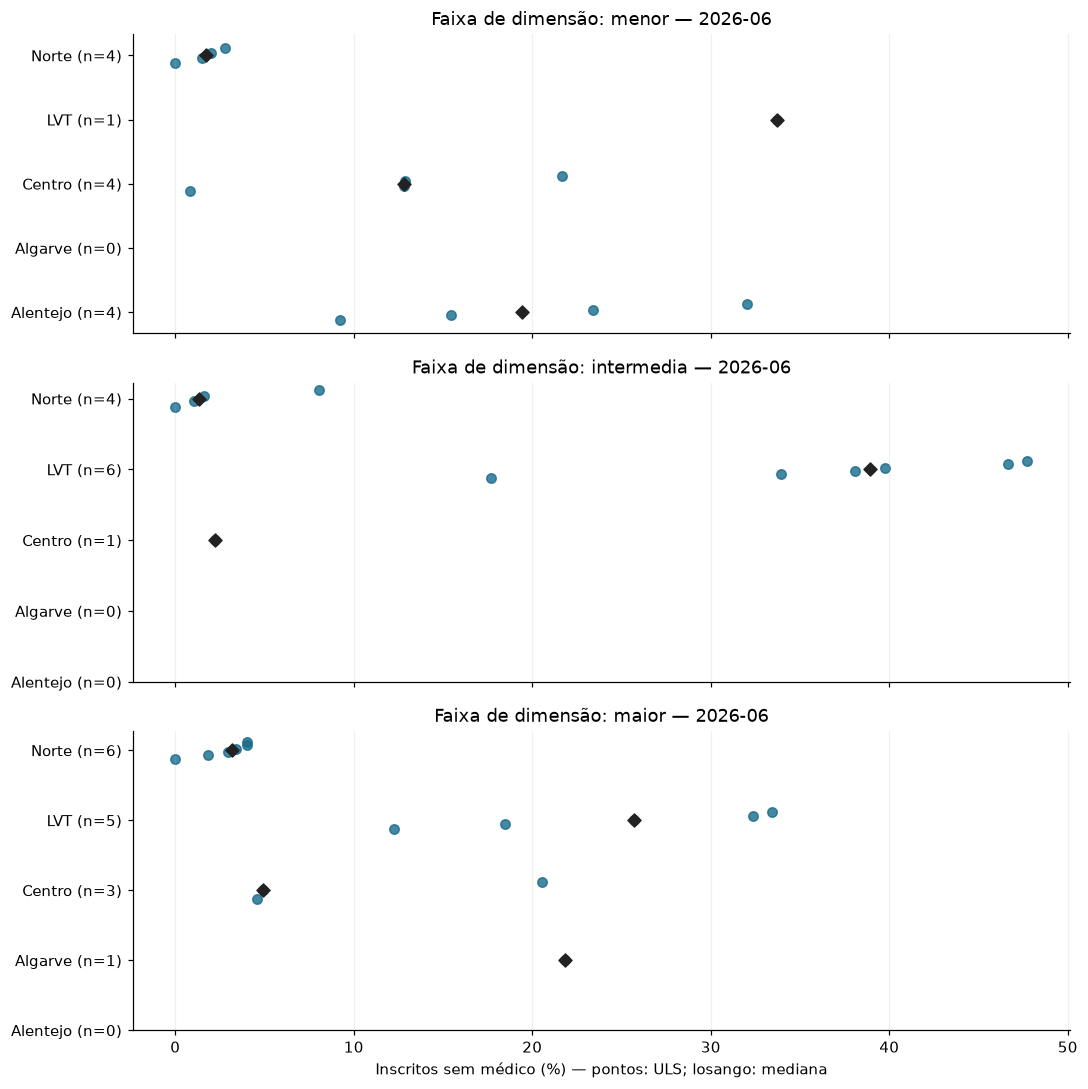

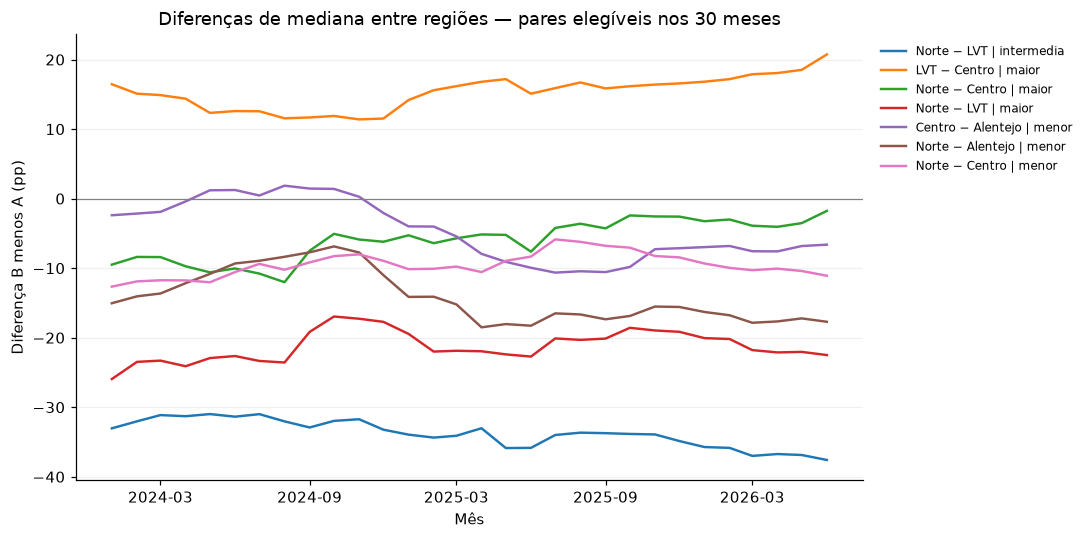

In [8]:
regioes = sorted(principal["regiao_saude"].unique())
abreviacoes = {"Lisboa e Vale do Tejo": "LVT", "Alentejo": "Alentejo", "Algarve": "Algarve", "Centro": "Centro", "Norte": "Norte"}
fig, axes = plt.subplots(3, 1, figsize=(10, 10), sharex=True)
for ax, faixa in zip(axes, ["menor", "intermedia", "maior"]):
    t = principal.loc[principal["mes"].eq(FIM) & principal["faixa_dimensao"].eq(faixa)]
    labels = []
    for y, regiao in enumerate(regioes):
        valores = t.loc[t["regiao_saude"].eq(regiao), "sem_medico_pct"].sort_values()
        labels.append(f"{abreviacoes.get(regiao, regiao)} (n={len(valores)})")
        if len(valores):
            deslocamento = np.linspace(-0.12, 0.12, len(valores)) if len(valores) > 1 else np.array([0.0])
            ax.scatter(valores, y + deslocamento, s=38, color="#176a8b", alpha=0.8)
            ax.scatter([valores.median()], [y], marker="D", color="#222222", s=36)
    ax.set_yticks(range(len(regioes)), labels)
    ax.set(title=f"Faixa de dimensão: {faixa} — {FIM:%Y-%m}")
    ax.grid(axis="x", alpha=0.18)
axes[-1].set_xlabel("Inscritos sem médico (%) — pontos: ULS; losango: mediana")
guardar_grafico(fig, "05_h4_regiao_dimensao.png")

if not pares_completos.empty:
    fig, ax = plt.subplots(figsize=(10, 5))
    for row in pares_completos.itertuples():
        t = comparacoes.loc[comparacoes["faixa_dimensao"].eq(row.faixa_dimensao) &
                            comparacoes["regiao_a"].eq(row.regiao_a) & comparacoes["regiao_b"].eq(row.regiao_b)]
        label = f"{abreviacoes.get(row.regiao_b, row.regiao_b)} − {abreviacoes.get(row.regiao_a, row.regiao_a)} | {row.faixa_dimensao}"
        ax.plot(t["mes"], t["diferenca_b_menos_a_pp"], label=label, linewidth=1.6)
    ax.axhline(0, color="gray", linewidth=0.8)
    ax.set(title="Diferenças de mediana entre regiões — pares elegíveis nos 30 meses", xlabel="Mês", ylabel="Diferença B menos A (pp)")
    ax.xaxis.set_major_locator(mdates.MonthLocator(interval=6))
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y-%m"))
    ax.legend(loc="upper left", bbox_to_anchor=(1.01, 1), frameon=False, fontsize=8)
    ax.grid(axis="y", alpha=0.18)
    guardar_grafico(fig, "05_h4_diferencas_temporais.png")
else:
    print("Não há pares de regiões/faixa elegíveis nos 30 meses. Não produzir uma comparação temporal completa.")

## 9. Responder às perguntas e avaliar as hipóteses

As respostas seguintes são produzidas a partir desta execução. Não são preenchidas antecipadamente para confirmar as hipóteses.

Para a H4, a existência de diferenças dentro das faixas permite uma conclusão descritiva limitada; não equivale a controlar exatamente a dimensão. Para a H3, vamos distinguir uma associação observada de uma explicação. Para a Q5, vamos indicar explicitamente que não foi avaliada nesta versão.

Na previsão, mostramos todos os candidatos finais, mas mantemos a escolha pela validação. Depois de ver o teste, novas tentativas exigiriam outro período de avaliação independente para não transformar o teste em mais um conjunto de ajuste.

As hipóteses incluem uma explicação em linguagem simples, um exemplo fictício e a utilidade da comparação. Os resultados reais e os detalhes técnicos continuam separados dos exemplos e são calculados nesta execução.


In [9]:
if supera_referencia:
    resposta_q6 = f"A abordagem selecionada ({ROTULOS[selecionado]}) teve MAE {mae_selecionado:.3f} pp, face a {mae_ref:.3f} pp da referência; ganho {ganho_selecionado:.3f} pp neste teste. Avaliar a consistência e a dimensão prática do ganho."
else:
    resposta_q6 = f"A referência teve MAE {mae_ref:.3f} pp. O melhor candidato aprendido escolhido na validação ({ROTULOS[melhor_aprendido_validacao]}) teve MAE {mae_aprendido_validacao:.3f} pp no teste. A escolha final do 04 foi {ROTULOS[selecionado]} e não superou a referência. O critério preditivo não foi cumprido; os resultados dos candidatos estão na tabela, sem nova seleção pelo teste."
perguntas = pd.DataFrame([
    ["Q1", "Onde há mais inscritos sem médico?", f"{lider_numero['unidade_fonte']}: {int(lider_numero['sem_medico']):,} inscritos sem médico em {FIM:%Y-%m}.", "respondida"],
    ["Q2", "Onde a percentagem é maior e como se distribui por região?", f"{lider_pct['unidade_fonte']}: {lider_pct['sem_medico_pct']:.2f}%. Rankings e tabelas geográficas guardados; inscritos são o denominador.", "respondida"],
    ["Q3", "Que unidades melhoraram ou pioraram?", f"Nas {len(evolucao)} séries completas, {melhorou} reduziram e {piorou} aumentaram a percentagem. Maior redução: {maior_melhoria['unidade_fonte']} ({maior_melhoria['variacao_sem_medico_pp']:.2f} pp); maior aumento: {maior_agravamento['unidade_fonte']} ({maior_agravamento['variacao_sem_medico_pp']:.2f} pp).", "respondida com restrição de continuidade"],
    ["Q4", "Como evoluiu a cobertura regional?", "As variações regionais foram calculadas a partir dos totais de todos os registos mensais. Ver 05_evolucao_regioes.csv; evolução não uniforme.", "respondida"],
    ["Q5", "Há associação com a utilização de consultas?", "Não avaliada nesta versão: falta confirmar a janela exata do indicador de um ano. Taxas preservadas, sem conclusões sobre consultas.", "pendente de definição"],
    ["Q6", "O histórico melhora a previsão do mês seguinte?", resposta_q6, "avaliada no teste reservado"],
], columns=["id", "pergunta", "resposta", "estado"])
if comparacoes.empty:
    leitura_h4 = "Dados insuficientes segundo a regra de grupos: sem pares elegíveis para comparar medianas entre regiões na mesma faixa."
else:
    leitura_h4 = f"Há diferenças descritivas entre regiões dentro de faixas comuns; {len(pares_completos)} pares são elegíveis nos 30 meses."
    if not pares_ultimo.empty:
        destaque = pares_ultimo.loc[pares_ultimo["diferenca_b_menos_a_pp"].abs().idxmax()]
        leitura_h4 += f" No último mês, a maior diferença elegível foi {abs(destaque['diferenca_b_menos_a_pp']):.2f} pp entre {destaque['regiao_a']} e {destaque['regiao_b']}, na faixa {destaque['faixa_dimensao']} (n={int(destaque['unidades_a'])} e n={int(destaque['unidades_b'])})."
    leitura_h4 += " Faixas aproximam dimensão; grupos pequenos e composição limitam a leitura. Sem efeito causal demonstrado."
# A redação usa os resultados desta execução. Os exemplos são fictícios.
# As explicações são guardadas no CSV/JSON para o 06 não ter números escritos à mão.
sem_variacao = len(evolucao) - melhorou - piorou
texto_h2 = (
    f"Entre {INICIO:%Y-%m} e {FIM:%Y-%m}, a percentagem de inscritos sem médico "
    f"diminuiu em {melhorou} unidades e aumentou em {piorou}, "
    f"nas {len(evolucao)} unidades com histórico completo."
)
if sem_variacao:
    texto_h2 += f" Em {sem_variacao}, não houve variação entre os extremos."

if pd.isna(rho_h3):
    texto_h3 = "Não foi possível calcular uma associação com as variações disponíveis."
    leitura_h3 = "Não há informação suficiente para interpretar a associação nesta execução."
else:
    # 0,3 é apenas uma referência descritiva de intensidade, não um teste estatístico.
    if abs(rho_h3) < 0.3:
        texto_h3 = "Encontrámos uma relação fraca entre as duas mudanças, com muitas exceções."
    else:
        texto_h3 = "Encontrámos uma associação entre as duas mudanças."
    if rho_h3 > 0:
        texto_h3 += " A tendência foi para maior crescimento dos inscritos acompanhar maior aumento da percentagem sem médico."
    elif rho_h3 < 0:
        texto_h3 += " A tendência foi para maior crescimento dos inscritos acompanhar menor aumento, ou maior redução, da percentagem sem médico."
    else:
        texto_h3 += " O valor calculado foi zero: não se observou uma direção nesta associação por posições."
    leitura_h3 = (
        "Esta comparação resume a mudança entre o início e o fim do período. "
        "Não demonstra que o crescimento tenha causado o agravamento, nem que a relação se repita todos os meses."
    )

if comparacoes.empty:
    texto_h4 = "Não há grupos com unidades suficientes para comparar regiões dentro das mesmas faixas de dimensão."
else:
    texto_h4 = (
        "A comparação usa a mediana: o valor central das percentagens das unidades de cada grupo. "
    )
    if not pares_ultimo.empty:
        destaque = pares_ultimo.loc[pares_ultimo["diferenca_b_menos_a_pp"].abs().idxmax()]
        diferenca_h4 = f"{abs(destaque['diferenca_b_menos_a_pp']):.2f}".replace(".", ",")
        faixa_h4 = {"menor": "menor", "intermedia": "intermédia", "maior": "maior"}.get(
            destaque["faixa_dimensao"], destaque["faixa_dimensao"])
        texto_h4 += (
            f"Em {FIM:%Y-%m}, a maior diferença elegível foi de {diferenca_h4} pontos percentuais "
            f"entre {destaque['regiao_a']} e {destaque['regiao_b']}, na faixa {faixa_h4}. "
            f"Foram comparados grupos de {int(destaque['unidades_a'])} e {int(destaque['unidades_b'])} unidades."
        )
    else:
        texto_h4 += "Não há pares elegíveis no último mês; as comparações dos outros meses estão guardadas."

hipoteses = pd.DataFrame([
    {
        "id": "H1",
        "hipotese": "Mais pessoas afetadas e maior percentagem são coisas diferentes",
        "explicacao": "Uma unidade pode ter mais inscritos sem médico, mas uma percentagem menor do seu total.",
        "evidencia": (
            f"Em {FIM:%Y-%m}, {posicoes_diferentes} das {len(ultimo)} unidades mudam de posição "
            "quando usamos número ou percentagem. Mudar de posição não significa, por si só, "
            "que os rankings sejam completamente diferentes."
        ),
        "exemplo": (
            "Uma unidade com 40 mil pessoas sem médico em 200 mil inscritos tem 20% sem médico. "
            "Outra com 20 mil em 50 mil tem 40%. A primeira tem mais pessoas afetadas; "
            "a segunda tem uma maior proporção afetada."
        ),
        "utilidade": "Perceber a dimensão do problema através das duas medidas e identificar situações que merecem atenção por motivos diferentes.",
        "avaliacao": "A hipótese é sustentada no último mês; convém consultar os dois rankings." if posicoes_diferentes else "As posições coincidem no último mês, embora as medidas tenham significados diferentes.",
        "detalhe_tecnico": (
            f"Spearman entre os rankings: {rho_rankings:.3f}. Valores próximos de 1 indicam "
            "uma ordenação semelhante; uma troca de apenas uma posição já conta como diferença."
        ),
    },
    {
        "id": "H2",
        "hipotese": "Algumas unidades melhoraram e outras pioraram" if melhorou and piorou else "Acompanhar a mudança da percentagem sem médico",
        "explicacao": "Comparamos a percentagem de inscritos sem médico no início e no fim do período, nas unidades com histórico completo.",
        "evidencia": texto_h2,
        "exemplo": (
            "Passar de 30% para 20% significa uma redução de 10 pontos percentuais. "
            "Passar de 20% para 30% representa um agravamento de igual dimensão."
        ),
        "utilidade": "Identificar unidades onde interessa investigar o que contribuiu para a melhoria ou para o agravamento.",
        "avaliacao": "A evolução do conjunto pode esconder situações locais diferentes. Estes dados não explicam as causas das mudanças.",
        "detalhe_tecnico": (
            f"A evolução por unidade usa {len(evolucao)} séries completas. A correspondência territorial "
            "dos dois nomes da Póvoa/Vila do Conde continua por confirmar e não foi unida automaticamente. "
            "A comparação dos extremos não descreve cada subida ou descida mensal."
        ),
    },
    {
        "id": "H3",
        "hipotese": "Mais inscritos nem sempre significam maior percentagem sem médico",
        "explicacao": (
            f"Nas {len(evolucao)} unidades com histórico completo, comparámos o crescimento do total "
            "de inscritos com a mudança na percentagem sem médico."
        ),
        "evidencia": texto_h3,
        "exemplo": (
            "Uma unidade pode passar de 100 mil para 110 mil inscritos e de 20 mil para 22 mil sem médico. "
            "Há mais pessoas sem médico, mas a percentagem mantém-se nos 20%."
        ),
        "utilidade": "Perceber se as duas mudanças tendem a acompanhar-se e orientar uma investigação com mais informação.",
        "avaliacao": leitura_h3,
        "detalhe_tecnico": (
            f"Spearman das variações: {rho_h3:.3f}, em {len(evolucao)} séries. "
            "Compara as posições das unidades nas duas variações. A designação de relação fraca "
            "usa |Spearman| < 0,3 como referência descritiva; não foi feito um teste de significância."
        ),
    },
    {
        "id": "H4",
        "hipotese": "Comparar regiões em unidades de dimensão semelhante",
        "explicacao": "Agrupámos as unidades pelo número de inscritos e comparámos regiões dentro das mesmas faixas de dimensão.",
        "evidencia": texto_h4,
        "exemplo": (
            "Se um grupo tiver um valor central de 40% e outro de 10%, "
            "a diferença é de 30 pontos percentuais. São grupos de unidades, não grupos de pessoas."
        ),
        "utilidade": "Identificar diferenças geográficas que merecem investigação, aproximando a dimensão das unidades comparadas.",
        "avaliacao": (
            "Os grupos são pequenos. Ter dimensão semelhante não significa ter os mesmos recursos ou características. "
            "A comparação não demonstra que a região seja a causa da diferença."
        ) if not comparacoes.empty else "Dados insuficientes segundo a regra de grupos; não concluir que as regiões são iguais.",
        "detalhe_tecnico": (
            f"Há {len(pares_completos)} combinações de duas regiões e uma faixa com grupos elegíveis "
            f"durante os {principal['mes'].nunique()} meses. Exigimos pelo menos três unidades em cada grupo. "
            "Os limites das faixas são fixos, definidos em janeiro de 2024. "
            "A mediana das percentagens das unidades não é a percentagem regional calculada pelos totais. "
            + leitura_h4
        ),
    },
], columns=["id", "hipotese", "evidencia", "avaliacao", "explicacao", "exemplo", "utilidade", "detalhe_tecnico"])
guardar_csv(perguntas, "05_respostas_perguntas.csv")
guardar_csv(hipoteses, "05_avaliacao_hipoteses.csv")
display(perguntas)
display(hipoteses)

,id,pergunta,resposta,estado
0,Q1,Onde há mais inscritos sem médico?,"CSP da ULS Amadora / Sintra: 194,681 inscritos...",respondida
1,Q2,Onde a percentagem é maior e como se distribui...,CSP da ULS Estuário do Tejo: 47.74%. Rankings ...,respondida
2,Q3,Que unidades melhoraram ou pioraram?,"Nas 38 séries completas, 19 reduziram e 19 aum...",respondida com restrição de continuidade
3,Q4,Como evoluiu a cobertura regional?,As variações regionais foram calculadas a part...,respondida
4,Q5,Há associação com a utilização de consultas?,Não avaliada nesta versão: falta confirmar a j...,pendente de definição
5,Q6,O histórico melhora a previsão do mês seguinte?,A referência teve MAE 0.417 pp. O melhor candi...,avaliada no teste reservado


,id,hipotese,evidencia,avaliacao,explicacao,exemplo,utilidade,detalhe_tecnico
0,H1,Mais pessoas afetadas e maior percentagem são ...,"Em 2026-06, 35 das 39 unidades mudam de posiçã...",A hipótese é sustentada no último mês; convém ...,Uma unidade pode ter mais inscritos sem médico...,Uma unidade com 40 mil pessoas sem médico em 2...,Perceber a dimensão do problema através das du...,Spearman entre os rankings: 0.938. Valores pró...
1,H2,Algumas unidades melhoraram e outras pioraram,"Entre 2024-01 e 2026-06, a percentagem de insc...",A evolução do conjunto pode esconder situações...,Comparamos a percentagem de inscritos sem médi...,Passar de 30% para 20% significa uma redução d...,Identificar unidades onde interessa investigar...,A evolução por unidade usa 38 séries completas...
2,H3,Mais inscritos nem sempre significam maior per...,Encontrámos uma relação fraca entre as duas mu...,Esta comparação resume a mudança entre o iníci...,"Nas 38 unidades com histórico completo, compar...",Uma unidade pode passar de 100 mil para 110 mi...,Perceber se as duas mudanças tendem a acompanh...,"Spearman das variações: 0.225, em 38 séries. C..."
3,H4,Comparar regiões em unidades de dimensão semel...,A comparação usa a mediana: o valor central da...,Os grupos são pequenos. Ter dimensão semelhant...,Agrupámos as unidades pelo número de inscritos...,Se um grupo tiver um valor central de 40% e ou...,Identificar diferenças geográficas que merecem...,Há 7 combinações de duas regiões e uma faixa c...


## 10. Avaliar os critérios de sucesso e decidir o que disponibilizar

O projeto pode responder ao problema de acompanhamento mesmo sem melhorar a previsão. Vamos separar o valor das respostas descritivas do critério preditivo.

A seleção por validação e os resultados do teste serão apresentados juntos. Os erros por unidade e mês acompanham a média global. Não definimos utilidade operacional a partir de uma melhoria pequena, nem estimamos quantos médicos contratar com esta fonte.

O produto pode seguir para disponibilização como análise histórica, com os dados, gráficos e limitações. A categoria por opção continua separada; inscritos não são população residente; a análise termina em junho de 2026.

In [10]:
criterios = pd.DataFrame([
    ["Resposta ao problema", "Q1 a Q4 respondidas; Q5 condicional; Q6 avaliada", "cumprido no âmbito definido", "Q5 pendente de definição; quatro hipóteses avaliadas com limites explícitos."],
    ["Qualidade dos dados", "Chaves, meses, categorias e observados coerentes", "cumprido nesta recolha", "Verificações aprovadas; nenhuma correção silenciosa nesta fase."],
    ["Comparabilidade", "Recorte e correspondências documentados", "cumprido com restrições", "2024–2026; 38 séries na evolução/previsão; duas designações não ligadas sem confirmação."],
    ["Reprodutibilidade", "Fonte, entrada, seleção e transformações rastreáveis", "cumprido na execução verificada", "Assinaturas e resultados guardados; executar sobre os ficheiros locais do 03/04."],
    ["Previsão", "Abordagem selecionada com MAE inferior ao último valor", "cumprido neste teste" if supera_referencia else "não cumprido neste teste", resposta_q6],
    ["Interpretação", "Ganho, erros por mês/unidade e limites apresentados", "cumprido", "Não atribuir causa às associações nem extrapolar para o indicador novo."],
], columns=["dimensao", "criterio", "resultado", "observacao"])
guardar_csv(criterios, "05_criterios_sucesso.csv")
display(criterios)
if supera_referencia:
    decisao_previsao = "A seleção apresentou ganho neste teste; disponibilizar a comparação histórica com análise da consistência, sem presumir uso operacional."
else:
    decisao_previsao = "Manter a referência simples como comparação principal; não foi demonstrado ganho da abordagem selecionada. Disponibilizar também os resultados dos modelos para transparência."
print("Decisão sobre previsão:", decisao_previsao)
print("Decisão sobre o produto: avançar com a análise histórica e as limitações documentadas.")

,dimensao,criterio,resultado,observacao
0,Resposta ao problema,Q1 a Q4 respondidas; Q5 condicional; Q6 avaliada,cumprido no âmbito definido,Q5 pendente de definição; quatro hipóteses ava...
1,Qualidade dos dados,"Chaves, meses, categorias e observados coerentes",cumprido nesta recolha,Verificações aprovadas; nenhuma correção silen...
2,Comparabilidade,Recorte e correspondências documentados,cumprido com restrições,2024–2026; 38 séries na evolução/previsão; dua...
3,Reprodutibilidade,"Fonte, entrada, seleção e transformações rastr...",cumprido na execução verificada,Assinaturas e resultados guardados; executar s...
4,Previsão,Abordagem selecionada com MAE inferior ao últi...,não cumprido neste teste,A referência teve MAE 0.417 pp. O melhor candi...
5,Interpretação,"Ganho, erros por mês/unidade e limites apresen...",cumprido,Não atribuir causa às associações nem extrapol...


Decisão sobre previsão: Manter a referência simples como comparação principal; não foi demonstrado ganho da abordagem selecionada. Disponibilizar também os resultados dos modelos para transparência.
Decisão sobre o produto: avançar com a análise histórica e as limitações documentadas.


## 11. Guardar a avaliação e as pendências

As tabelas e gráficos ficam em `data/analytics/`. Os erros linha a linha e o resumo da avaliação ficam em `data/output/`; as conclusões legíveis ficam em `docs/`.

| Ficheiro | Finalidade |
|---|---|
| `05_metricas_teste.csv` | Comparação das três abordagens nas mesmas linhas. |
| `05_erros_por_mes.csv` / `05_erros_por_unidade.csv` | Consistência e situações com maior erro. |
| `05_respostas_perguntas.csv` / `05_avaliacao_hipoteses.csv` | Respostas e avaliação das hipóteses. |
| `05_h4_comparacoes_regioes.csv` / `05_h4_consistencia_temporal.csv` | Comparação geográfica e cobertura temporal dos pares. |
| `05_criterios_sucesso.csv` | Avaliação do âmbito e do critério preditivo. |
| `sns_avaliacao_resumo.json` | Resumo reutilizável para disponibilização. |
| `05_conclusoes_avaliacao.md` | Conclusões, decisões e limitações. |

Continuam pendentes a correspondência territorial da Póvoa/Vila do Conde e a janela exata das taxas de consultas. São limites conhecidos desta versão, não confirmações feitas por conveniência.

In [11]:
assinaturas_depois = {p.relative_to(raiz).as_posix(): sha256(p) for p in entradas}
if assinaturas_depois != assinaturas_antes:
    raise ValueError("Uma entrada mudou durante a avaliação.")
resumo = {
    "periodo_principal": {"inicio": INICIO.strftime("%Y-%m"), "fim": FIM.strftime("%Y-%m")},
    "recolhido_em_utc": manifesto["recolhido_em_utc"],
    "teste": {"primeiro_mes_alvo": MESES_TESTE.min().strftime("%Y-%m"), "ultimo_mes_alvo": MESES_TESTE.max().strftime("%Y-%m"),
              "linhas": len(previsoes), "unidades": int(previsoes["unidade_fonte"].nunique())},
    "selecionado_no_04": selecionado, "selecao_mantida": True,
    "metricas_teste": metricas.to_dict("records"), "ganho_selecionado_pp": ganho_selecionado,
    "criterio_preditivo_cumprido": bool(supera_referencia), "decisao_previsao": decisao_previsao,
    "h1": {"posicoes_diferentes": posicoes_diferentes, "spearman_rankings": rho_rankings},
    "h2": {"series_completas": len(evolucao), "com_reducao": melhorou, "com_aumento": piorou},
    "h3": {"spearman_variacoes": rho_h3, "unidades": len(evolucao)},
    "h4": {"pares_elegiveis_nos_30_meses": len(pares_completos), "grupos_pequenos_ultimo_mes": int(h4_ultimo["grupo_pequeno"].sum()), "leitura": leitura_h4},
    "perguntas": perguntas.to_dict("records"), "hipoteses": hipoteses.to_dict("records"), "criterios": criterios.to_dict("records"),
    "pendencias": ["Correspondência territorial da Póvoa/Vila do Conde", "Janela exata das taxas de consultas de um ano"],
    "limites": ["Histórico antigo; sem extrapolação para julho de 2026", "38 séries completas na evolução/previsão", "Nomes estáveis não comprovam território estável", "Recolha atual pode incluir revisões", "Meses e unidades não são observações independentes", "Faixas de dimensão aproximadas e grupos pequenos na H4", "Inscritos não são população residente; sem médico por opção separado", "Resultados descritivos não identificam causas"],
    "input_sha256": assinaturas_antes, "entradas_preservadas": True,
}
(PASTA_OUTPUT / "sns_avaliacao_resumo.json").write_text(json.dumps(resumo, ensure_ascii=False, indent=2), encoding="utf-8")
nota = "# Fase 5 — Conclusões da avaliação\n\n"
nota += f"Recolha: {manifesto['recolhido_em_utc']} (UTC). Âmbito: {INICIO:%Y-%m} a {FIM:%Y-%m}.\n\n"
nota += "## Previsão\n\n" + resposta_q6 + "\n\n"
for row in metricas.itertuples():
    nota += f"- {ROTULOS[row.abordagem]}: MAE {row.mae_pp:.6f} pp; RMSE {row.rmse_pp:.6f} pp; viés {row.vies_pp:.6f} pp.\n"
nota += "\nSeleção feita pela validação e mantida na avaliação. Mesmas unidades e meses para as abordagens. Teste com seis meses-alvo e 38 unidades; modelos fixos com origens mensais móveis. Não houve novo treino nesta fase.\n\n"
nota += "## Perguntas e hipóteses\n\n"
for row in perguntas.itertuples():
    nota += f"- {row.id}: {row.resposta} Estado: {row.estado}.\n"
nota += "\n"
for row in hipoteses.itertuples():
    nota += f"\n### {row.id} — {row.hipotese}\n\n{row.explicacao}\n\n"
    nota += f"**O que encontrámos:** {row.evidencia}\n\n"
    nota += f"**Exemplo fictício:** {row.exemplo}\n\n"
    nota += f"**Para que serve:** {row.utilidade}\n\n"
    nota += f"**Como interpretar:** {row.avaliacao}\n\n"
    nota += f"**Detalhe técnico:** {row.detalhe_tecnico}\n"
nota += "\n## Decisão\n\n" + decisao_previsao + "\n\nAvançar para disponibilização da análise histórica com as respostas, tabelas e gráficos. O critério preditivo é avaliado separadamente do valor descritivo.\n\n"
nota += "## Limitações e pendências\n\n" + "\n".join("- " + x for x in resumo["limites"])
nota += "\n\nPendentes: correspondência territorial da Póvoa/Vila do Conde e janela exata das taxas de consultas. Nenhum resultado demonstra causalidade ou determina distribuição de recursos.\n"
(PASTA_DOCS / "05_conclusoes_avaliacao.md").write_text(nota, encoding="utf-8")
print("Avaliação concluída. Resultados e conclusões guardados; seleção do 04 mantida.")

Avaliação concluída. Resultados e conclusões guardados; seleção do 04 mantida.


## Próxima fase

[Avançar para o 06 — Disponibilização](./06_deployment.ipynb)

Na fase seguinte vamos organizar a apresentação da análise histórica e as instruções para a reproduzir. O link abre o notebook quando o `06_deployment.ipynb` estiver na mesma pasta `notebooks/`.